# Лабораторная работа № 2
## K-means


## Импорт библиотек


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, cut_tree
from scipy.optimize import linear_sum_assignment


## Подготовка данных


In [ ]:
# Загружаем исходную таблицу и отмечаем пропуски.
DATA_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/lab2/Econom_Cities_data.csv"
raw2 = pd.read_csv(DATA_URL, sep=';', decimal=',', na_values=[-9999])
features2 = ['Work', 'Price', 'Salary']
# Удаляем города с неполными данными.
cities2 = raw2.dropna(subset=features2).copy().reset_index(drop=True)
# Приводим признаки к одному масштабу и выводим сводку по данным.
scaler2 = StandardScaler()
X2 = scaler2.fit_transform(cities2[features2])
display(raw2[features2].isna().sum().to_frame('Пропуски'))
print('В анализе:', len(cities2), 'городов')


,Пропуски
Work,2
Price,0
Salary,2


В анализе: 46 городов


In [ ]:
# Загружаем показатели стран за 1991 год и сопоставляем города со странами.
COUNTRIES_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/countries_1991.csv"
country_indicators = pd.read_csv(COUNTRIES_URL)
city_country = {
    'Amsterdam': 'Нидерланды',
    'Athens': 'Греция',
    'Bogota': 'Колумбия',
    'Bombay': 'Индия',
    'Brussels': 'Бельгия',
    'Buenos_Aires': 'Аргентина',
    'Cairo': 'Египет',
    'Caracas': 'Венесуэла',
    'Chicago': 'США',
    'Copenhagen': 'Дания',
    'Dublin': 'Ирландия',
    'Dusseldorf': 'Германия',
    'Frankfurt': 'Германия',
    'Geneva': 'Швейцария',
    'Helsinki': 'Финляндия',
    'Hong_Kong': 'Гонконг',
    'Houston': 'США',
    'Jakarta': 'Индонезия',
    'Johannesburg': 'ЮАР',
    'Kuala_Lumpur': 'Малайзия',
    'Lagos': 'Нигерия',
    'Lisbon': 'Португалия',
    'London': 'Великобритания',
    'Los_Angeles': 'США',
    'Luxembourg': 'Люксембург',
    'Madrid': 'Испания',
    'Manila': 'Филиппины',
    'Mexico_City': 'Мексика',
    'Milan': 'Италия',
    'Montreal': 'Канада',
    'Nairobi': 'Кения',
    'New_York': 'США',
    'Nicosia': 'Кипр',
    'Oslo': 'Норвегия',
    'Panama': 'Панама',
    'Paris': 'Франция',
    'Rio_de_Janeiro': 'Бразилия',
    'San_Paulo': 'Бразилия',
    'Seoul': 'Южная Корея',
    'Singpore': 'Сингапур',
    'Stockholm': 'Швеция',
    'Sydney': 'Австралия',
    'Taipei': 'Тайвань',
    'Tel_Aviv': 'Израиль',
    'Tokyo': 'Япония',
    'Toronto': 'Канада',
    'Vienna': 'Австрия',
    'Zurich': 'Швейцария',
}
external_features = ['HDI', 'Life_expectancy']


# Присоединяем национальные показатели к городам.
def attach_country_indicators(city_data):
    external = city_data[['City']].copy()
    external['Country'] = external.City.map(city_country)
    return external.merge(country_indicators, on='Country', how='left',
                          validate='many_to_one', sort=False)


def compare_living_standards(city_data, cluster_labels, title, plots=True):
    # Присоединяем показатели стран к готовым назначениям городов.
    external = attach_country_indicators(city_data)
    external['Group'] = np.asarray(cluster_labels)
    complete = external.dropna(subset=external_features)
    clustered = complete.loc[complete.Group.ne(-1)].copy()
    print(title)
    print(f'Городов с двумя показателями: {len(complete)}/{len(external)}; '
          f'в кластерах: {len(clustered)}; шум с показателями: {complete.Group.eq(-1).sum()}')

    # Выводим средние, медианы и диапазоны показателей внутри групп.
    summary = complete.groupby('Group').agg(
        Cities=('City', 'size'), Countries=('Country', 'nunique'),
        HDI_mean=('HDI', 'mean'), HDI_median=('HDI', 'median'),
        HDI_min=('HDI', 'min'), HDI_max=('HDI', 'max'),
        Life_mean=('Life_expectancy', 'mean'),
        Life_median=('Life_expectancy', 'median'),
        Life_min=('Life_expectancy', 'min'), Life_max=('Life_expectancy', 'max'))
    summary.index = ['Шум' if g == -1 else f'Кластер {g}' for g in summary.index]
    display(summary.round(3))

    # Считаем долю различий, приходящуюся на различия между группами.
    def between_group_share(feature, weights):
        if clustered.Group.nunique() < 2:
            return np.nan
        overall = np.average(clustered[feature], weights=weights)
        total = np.sum(weights * (clustered[feature] - overall) ** 2)
        between = 0.0
        for _, group in clustered.groupby('Group'):
            group_weights = weights.loc[group.index]
            mean = np.average(group[feature], weights=group_weights)
            between += group_weights.sum() * (mean - overall) ** 2
        return between / total if total > 0 else np.nan

    # Повторяем оценку, уравнивая суммарный вес каждой страны.
    weights_city = pd.Series(1.0, index=clustered.index)
    weights_country = 1 / clustered.groupby('Country').City.transform('size')
    result = {'Городов в оценке': len(clustered),
              'Стран в оценке': clustered.Country.nunique()}
    for feature, name in [('HDI', 'ИЧР'), ('Life_expectancy', 'Продолжительность жизни')]:
        result[f'η²: {name}'] = between_group_share(feature, weights_city)
        result[f'η²: {name}, равный вес стран'] = between_group_share(feature, weights_country)

    if plots:
        # Показываем разброс показателей и расположение готовых групп.
        groups = sorted(complete.Group.unique(), key=lambda g: (g == -1, g))
        names = ['Шум' if g == -1 else f'Кластер {g}' for g in groups]
        fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
        for ax, feature, ylabel in [
            (axes[0], 'HDI', 'ИЧР'),
            (axes[1], 'Life_expectancy', 'Продолжительность жизни, лет')
        ]:
            ax.boxplot([complete.loc[complete.Group.eq(g), feature] for g in groups],
                       showfliers=False)
            ax.set_xticks(range(1, len(names) + 1))
            ax.set_xticklabels(names)
            for position, group in enumerate(groups, start=1):
                values = complete.loc[complete.Group.eq(group), feature].to_numpy()
                offsets = np.linspace(-.10, .10, len(values))
                ax.scatter(position + offsets, values, alpha=.65, s=26)
            ax.set(title=ylabel + ' по группам', ylabel=ylabel)
            ax.tick_params(axis='x', labelrotation=20)
            ax.grid(axis='y', alpha=.2)
        for group, name in zip(groups, names):
            part = complete.loc[complete.Group.eq(group)]
            axes[2].scatter(part.HDI, part.Life_expectancy,
                            label=name, marker='^' if group == -1 else 'o', alpha=.75)
        centers = clustered.groupby('Group')[external_features].mean()
        axes[2].scatter(centers.HDI, centers.Life_expectancy, marker='x', c='black',
                        s=120, linewidths=2, label='Средние показатели групп', zorder=5)
        axes[2].set(title='Группы по сторонним показателям', xlabel='ИЧР',
                    ylabel='Продолжительность жизни, лет')
        axes[2].legend()
        axes[2].grid(alpha=.2)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()
    return result


## Вспомогательные функции


In [ ]:
# Нумеруем группы по убыванию средней зарплаты.
def relabel_by_salary(data, group_labels):
    groups = data.assign(Group=np.asarray(group_labels))
    order = (groups.loc[groups.Group.ne(-1)].groupby('Group').Salary.mean()
             .sort_values(ascending=False).index)
    mapping = {old: new + 1 for new, old in enumerate(order)}
    return np.array([mapping[label] if label != -1 else -1 for label in group_labels])


# Выводим размеры, средние признаки и состав групп.
def show_cluster_summary(data, cluster_column, features, medians=False,
                         assignments=True, mean_suffix='', decimals=2):
    grouped = data.groupby(cluster_column)
    summary = grouped.agg(Cities=('City', 'size'),
                          **{feature + mean_suffix: (feature, 'mean') for feature in features})
    display(summary.round(decimals))
    if medians:
        display(grouped[features].median().round(decimals)
                .rename_axis(cluster_column + ': medians'))
    for cluster, group in grouped:
        name = 'Шум' if cluster == -1 else f'Кластер {cluster}'
        print(f'{name} ({len(group)} городов):',
              ', '.join(group.City.str.replace('_', ' ').sort_values()))
    if assignments:
        display(data.sort_values([cluster_column, 'City']).reset_index(drop=True))
    return summary


# Строим профили групп и все три парные диаграммы.
def plot_cluster_profiles(data, points, group_labels, features, title):
    plot_data = data.assign(Group=np.asarray(group_labels))
    clustered = plot_data.loc[plot_data.Group.ne(-1)]
    noise = plot_data.loc[plot_data.Group.eq(-1)]
    profiles = (pd.DataFrame(points, columns=features).assign(Group=np.asarray(group_labels))
                .loc[np.asarray(group_labels) != -1].groupby('Group').mean())
    centers = clustered.groupby('Group')[features].mean()
    axis_names = {'Work': 'Рабочее время, часов в год',
                  'Price': 'Индекс цен', 'Salary': 'Индекс почасовой зарплаты'}
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    axes = axes.ravel()
    profiles.T.plot.bar(ax=axes[0], rot=0)
    axes[0].axhline(0, linewidth=1)
    axes[0].set(title=title + ': стандартизированные средние', ylabel='Средний z-балл')
    axes[0].legend(title='Кластер')
    for ax, x, y, pair_title in [
        (axes[1], 'Price', 'Salary', 'Цены и зарплаты'),
        (axes[2], 'Work', 'Salary', 'Рабочее время и зарплата'),
        (axes[3], 'Work', 'Price', 'Рабочее время и цены')
    ]:
        for cluster, group in clustered.groupby('Group'):
            ax.scatter(group[x], group[y], s=55, alpha=.8,
                       label=f'Кластер {cluster} (n={len(group)})')
        if len(noise):
            ax.scatter(noise[x], noise[y], marker='^', s=75, label=f'Шум (n={len(noise)})')
        ax.scatter(centers[x], centers[y], marker='x', c='black', s=130,
                   linewidths=2, zorder=5, label='Центры кластеров')
        ax.set(title=title + ': ' + pair_title.lower(),
               xlabel=axis_names[x], ylabel=axis_names[y])
        ax.legend()
        ax.grid(alpha=.2)
    plt.tight_layout()
    plt.show()


# Исключаем по одному городу, повторяем разбиение и сравниваем назначения.
def check_leave_one_out(data, features, baseline, fit_labels):
    rows = []
    baseline = np.asarray(baseline)
    for i in range(len(data)):
        mask = np.arange(len(data)) != i
        points = StandardScaler().fit_transform(data.loc[mask, features])
        other = fit_labels(points)
        rows.append({'Excluded_city': data.iloc[i].City,
                     'ARI': adjusted_rand_score(baseline[mask], other)})
    return pd.DataFrame(rows)


# Повторяем разбиение при разных начальных состояниях.
def check_kmeans_seeds(points, baseline, k):
    rows = []
    for seed in range(30):
        repeat = KMeans(n_clusters=k, n_init=50, random_state=seed).fit(points)
        rows.append({'seed': seed, 'ARI': adjusted_rand_score(baseline, repeat.labels_),
                     'inertia': repeat.inertia_})
    return pd.DataFrame(rows)


## Кластеризация


In [ ]:
# Сравниваем качество разбиений на 2–8 групп.
km_models, km_rows = {}, []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X2)
    km_models[k] = model
    km_rows.append({'k': k, 'inertia': model.inertia_,
                    'silhouette': silhouette_score(X2, model.labels_),
                    'sizes': str(np.bincount(model.labels_).tolist())})
km_scores = pd.DataFrame(km_rows)
display(km_scores.round(4))
# Выбираем число групп по наибольшему силуэту.
km_k = int(km_scores.sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0]['k'])
km_model = km_models[km_k]
# Нумеруем группы по убыванию средней зарплаты и сохраняем назначения городов.
km_labels = relabel_by_salary(cities2, km_model.labels_)
cities2['KMeans'] = km_labels
print('KMEANS_RESULT', km_k, silhouette_score(X2, km_labels))
display(cities2.groupby('KMeans').agg(n=('City','size'), **{f:(f,'mean') for f in features2}).round(3))



,k,inertia,silhouette,sizes
0,2,61.1166,0.4705,"[21, 25]"
1,3,47.3610,0.3875,"[11, 25, 10]"
2,4,35.5528,0.3658,"[6, 11, 19, 10]"
3,5,27.7633,0.3750,"[6, 11, 14, 8, 7]"
4,6,23.2127,0.3730,"[5, 14, 7, 6, 8, 6]"
5,7,18.7006,0.3971,"[6, 9, 4, 7, 4, 2, 14]"
6,8,15.3090,0.3964,"[5, 4, 14, 8, 3, 2, 7, 3]"


KMEANS_RESULT 2 0.47049928674558456


,n,Work,Price,Salary
KMeans,,,,
1,25,1789.240,84.972,59.032
2,21,1987.857,52.395,16.348


### Выбор числа кластеров и профили групп


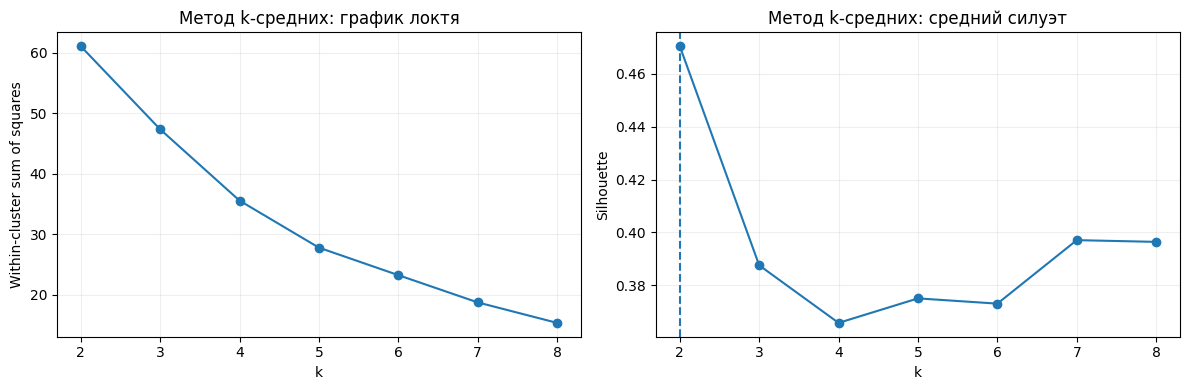

,Cities,Work,Price,Salary
KMeans,,,,
1,25,1789.24,84.97,59.03
2,21,1987.86,52.40,16.35


Кластер 1 (25 городов): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2 (21 городов): Athens, Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Taipei, Tel Aviv


,City,Work,Price,Salary,KMeans
0,Amsterdam,1714.0,65.6,49.0,1
1,Brussels,1708.0,73.8,50.5,1
2,Chicago,1924.0,73.9,61.9,1
3,Copenhagen,1717.0,91.3,62.9,1
4,Dublin,1759.0,76.0,41.4,1
5,Dusseldorf,1693.0,78.5,60.2,1
6,Frankfurt,1650.0,74.5,60.4,1
7,Geneva,1880.0,95.9,90.3,1
8,Helsinki,1667.0,113.6,66.6,1
9,Houston,1978.0,71.9,46.3,1


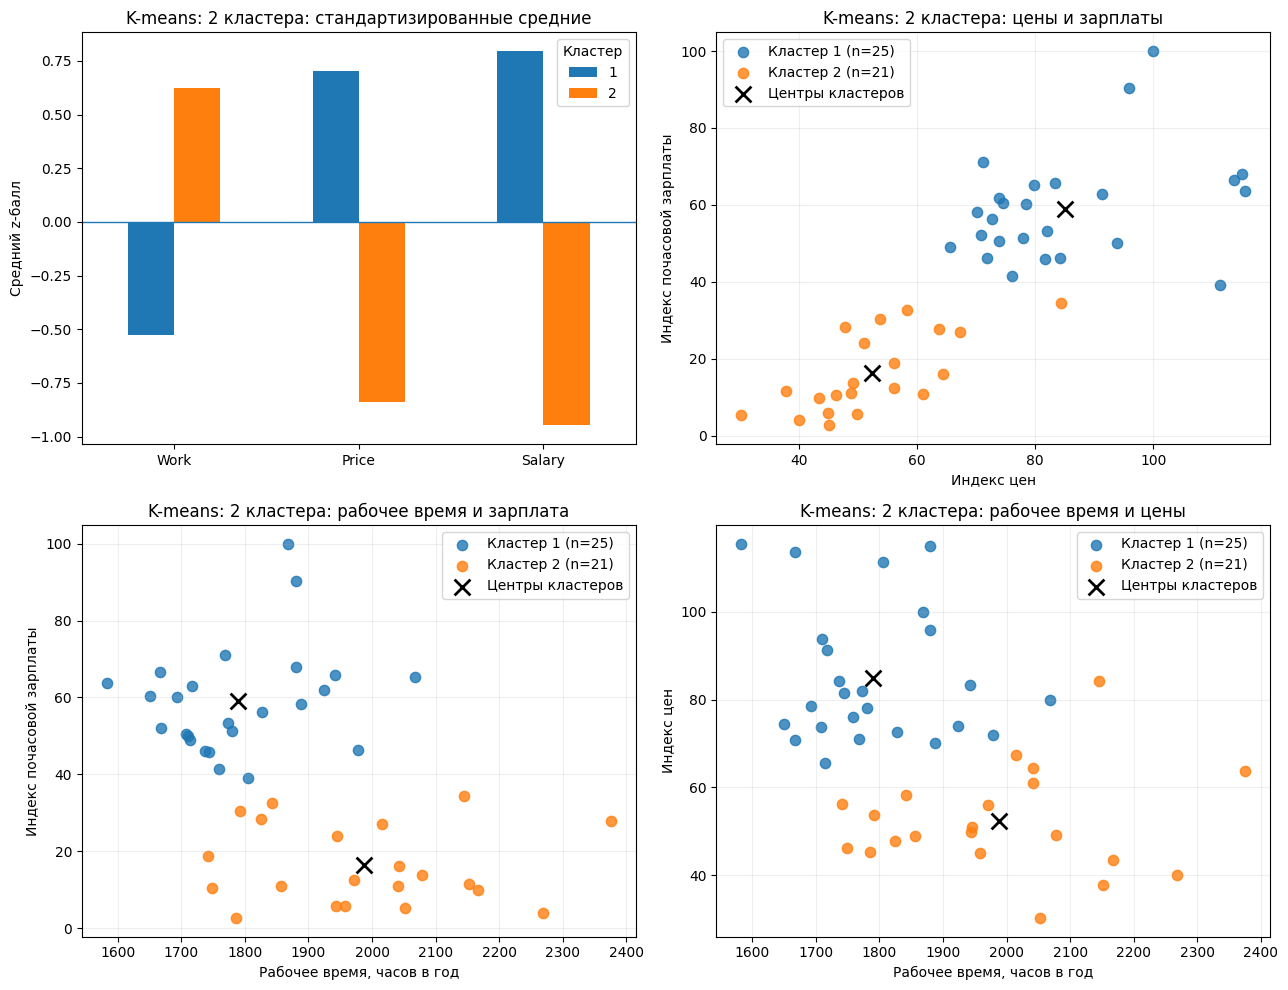

In [ ]:
# Сравниваем изменение инерции и силуэта с ростом числа групп.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(km_scores.k, km_scores.inertia, 'o-')
axes[0].set(title='Метод k-средних: график локтя', xlabel='k', ylabel='Within-cluster sum of squares', xticks=km_scores.k)
axes[1].plot(km_scores.k, km_scores.silhouette, 'o-')
axes[1].axvline(km_k, linestyle='--')
axes[1].set(title='Метод k-средних: средний силуэт', xlabel='k', ylabel='Silhouette', xticks=km_scores.k)
for ax in axes: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
# Показываем средние признаки и состав выбранных групп.
km_summary = show_cluster_summary(cities2, 'KMeans', features2)
plot_cluster_profiles(cities2, X2, km_labels, features2, f'K-means: {km_k} кластера')


### Силуэты городов и сравнение с Ward

Силуэт около 0 показывает размытую границу, отрицательный — меньшую среднюю дистанцию до другой группы. Таблица пересечений показывает совпадения между методами после согласования номеров кластеров.


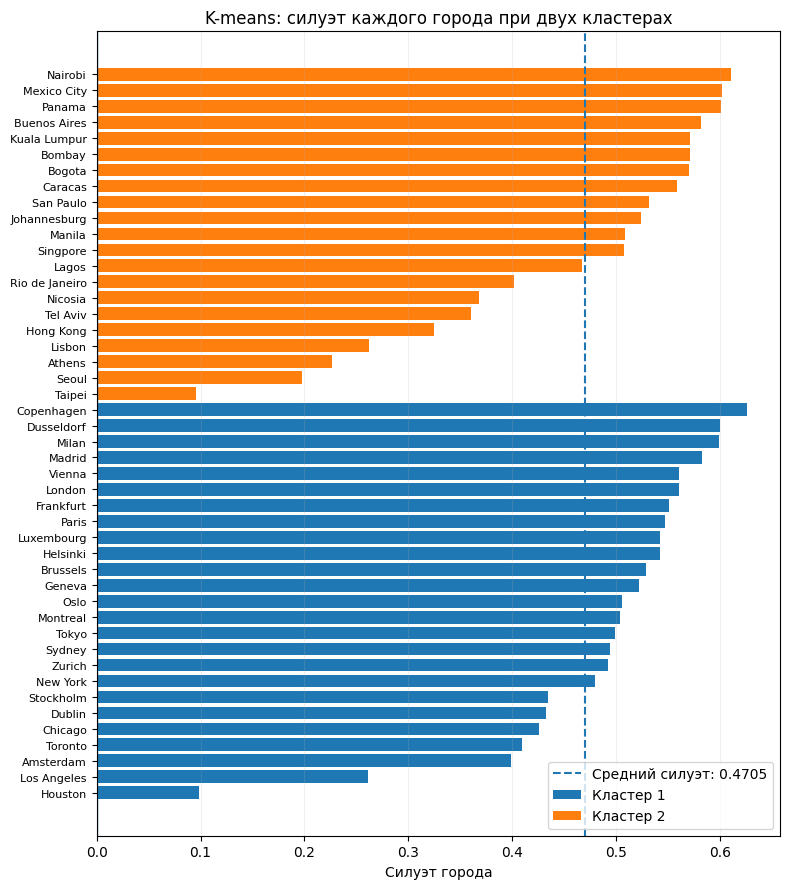

Городов с отрицательным силуэтом: 0
Города с силуэтом ниже 0,25:


,Город,Кластер,Силуэт
25,Taipei,2,0.0952
0,Houston,1,0.0985
26,Seoul,2,0.1975
27,Athens,2,0.2265


Ward и k-means при k=2, номера групп согласованы:


K-means,1,2
Ward,,
1,25,0
2,0,21


Городов с разными назначениями: 0


,Город,Work,Price,Salary,Ward,KMeans


In [ ]:
# Считаем силуэт каждого города и сортируем города внутри групп.
def show_city_silhouette(points, labels, city_names, title):
    values = silhouette_samples(points, labels)
    table = pd.DataFrame({'Город': np.asarray(city_names),
                          'Кластер': labels, 'Силуэт': values})
    table = table.sort_values(['Кластер', 'Силуэт']).reset_index(drop=True)
    # Строим график силуэтов городов.
    fig, ax = plt.subplots(figsize=(8, 9))
    for cluster, part in table.groupby('Кластер'):
        ax.barh(part.index, part['Силуэт'], label=f'Кластер {cluster}')
    ax.set_yticks(table.index, table['Город'].str.replace('_', ' '), fontsize=8)
    ax.axvline(0, linewidth=1)
    ax.axvline(values.mean(), linestyle='--', label=f'Средний силуэт: {values.mean():.4f}')
    ax.set(title=title, xlabel='Силуэт города')
    ax.legend()
    ax.grid(axis='x', alpha=.2)
    plt.tight_layout()
    plt.show()
    # Выводим города с низкими и отрицательными силуэтами.
    print('Городов с отрицательным силуэтом:', int((values < 0).sum()))
    print('Города с силуэтом ниже 0,25:')
    display(table.loc[table['Силуэт'] < .25].sort_values('Силуэт').round(4))

# Получаем второе разбиение и согласуем номера групп.
def compare_ward_kmeans(k, kmeans_labels):
    ward_labels = cut_tree(linkage(X2, method='ward'), n_clusters=k).ravel() + 1
    overlap = pd.crosstab(ward_labels, kmeans_labels)
    row_indices, column_indices = linear_sum_assignment(-overlap.to_numpy())
    matching = {overlap.index[i]: overlap.columns[j]
                for i, j in zip(row_indices, column_indices)}
    aligned_ward = np.array([matching[label] for label in ward_labels])
    # Показываем пересечения групп и города с разными назначениями.
    print(f'Ward и k-means при k={k}, номера групп согласованы:')
    display(pd.crosstab(pd.Series(aligned_ward, name='Ward'),
                        pd.Series(kmeans_labels, name='K-means')))
    moved = aligned_ward != kmeans_labels
    print('Городов с разными назначениями:', int(moved.sum()))
    display(cities2.loc[moved, ['City', 'Work', 'Price', 'Salary']]
            .assign(Ward=aligned_ward[moved], KMeans=kmeans_labels[moved])
            .rename(columns={'City': 'Город'}))

show_city_silhouette(X2, km_labels, cities2.City, 'K-means: силуэт каждого города при двух кластерах')
compare_ward_kmeans(km_k, km_labels)


При двух группах все силуэты положительные, но у Тайбэя, Хьюстона, Сеула и Афин они ниже 0,25. Таблица пересечений диагональная: Ward и k-means относят все 46 городов к одинаковым группам.


### Интерпретация, проверка и вывод

Выбран **k = 2**: средний силуэт **0,4705**. Кластеры содержат **25 и 21 город** и полностью совпадают с двухкластерным решением Ward из первой работы. Номера переупорядочены по средней зарплате для удобства сравнения.

| Группа | n | Work, среднее | Price, среднее | Salary, среднее | Смысл |
|---|---:|---:|---:|---:|---|
| 1 | 25 | 1789,24 | 84,97 | 59,03 | Более высокие цены и зарплаты, меньшее рабочее время |
| 2 | 21 | 1987,86 | 52,40 | 16,35 | Более низкие цены и зарплаты, большее рабочее время |


## Проверка чувствительности при двух кластерах


In [ ]:
# Сравниваем выбранное разбиение с результатом первой лабораторной.
ward2 = cut_tree(linkage(X2, method='ward'), n_clusters=2).ravel()
print('ARI k-means vs Ward:', adjusted_rand_score(km_labels, ward2))
# Повторяем кластеризацию с 30 случайными начальными состояниями.
km_repeats = check_kmeans_seeds(X2, km_labels, km_k)
seed_checks = {km_k: km_repeats}
display(km_repeats[['ARI','inertia']].agg(['min','median','max']).round(4))
# Сохраняем назначения городов, профили и оценки качества.
cities2.to_csv('lab2_kmeans_clusters.csv', index=False, encoding='utf-8-sig')
km_summary.to_csv('lab2_kmeans_profiles.csv', encoding='utf-8-sig')
km_scores.to_csv('lab2_kmeans_scores.csv', index=False, encoding='utf-8-sig')


ARI k-means vs Ward: 1.0


,ARI,inertia
min,1.0,61.1166
median,1.0,61.1166
max,1.0,61.1166


## Сравнение со сторонними показателями

Показатели за **1991 год**: ИЧР — от 0 до 1; ожидаемая продолжительность жизни при рождении — в годах, для обоих полов.
Источники: [ПРООН, исторический ряд ИЧР](https://hdr.undp.org/sites/default/files/2025_HDR/HDR25_Composite_indices_complete_time_series.csv) и [Всемирный банк, продолжительность жизни](https://data.worldbank.org/indicator/SP.DYN.LE00.IN).
Для Тайваня в этих источниках нет значений: Тайбэй сохраняется в исходной кластеризации, но пропускается во внешней оценке.

Кластеризация по-прежнему использует **только Work, Price и Salary**. Здесь проверяем, отличаются ли полученные группы по сторонним показателям.
В таблице средние и медианы рассчитаны по городам. Показатель **η²** показывает долю разброса стороннего признака, которая приходится на различия между средними групп: от 0 до 1, выше — сильнее разделение по этому признаку.
Дополнительно считаем η² с равным суммарным весом стран, чтобы несколько городов одной страны не усиливали её вклад.

Это описательная проверка соответствия, а не доказательство причинной связи. Национальные значения повторяются у городов одной страны; одна страна может встречаться в нескольких кластерах. Продолжительность жизни уже входит в ИЧР, поэтому эти две оценки взаимосвязаны. Рост η² при увеличении числа групп сам по себе не доказывает улучшение кластеризации.


Города без полного набора сторонних показателей:


,City,Country,HDI,Life_expectancy
40,Taipei,Тайвань,NaN,NaN


Основное разбиение
Городов с двумя показателями: 45/46; в кластерах: 45; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,25,19,0.841,0.848,0.774,0.878,76.395,76.192,75.025,79.037
Кластер 2,20,19,0.663,0.670,0.383,0.826,68.798,71.196,45.483,77.873


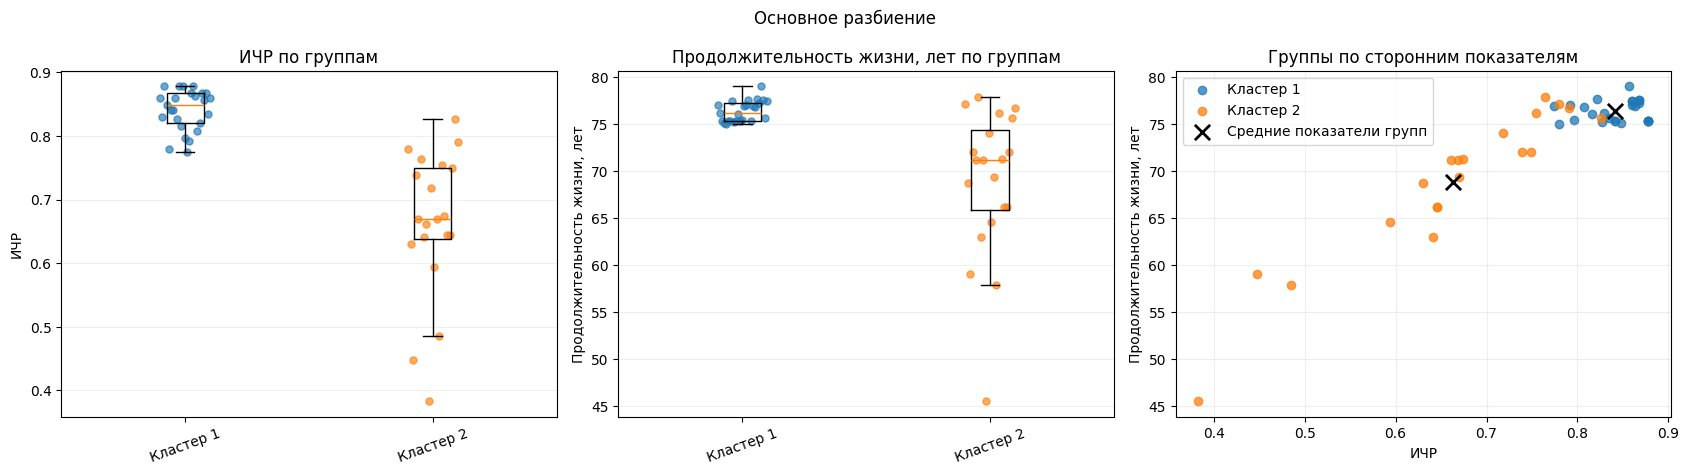

,Городов в оценке,Стран в оценке,η²: ИЧР,"η²: ИЧР, равный вес стран",η²: Продолжительность жизни,"η²: Продолжительность жизни, равный вес стран"
0,45,38,0.5563,0.4969,0.3414,0.3073


In [ ]:
# Сравниваем готовые группы по национальным показателям.
external_missing = attach_country_indicators(cities2)
print('Города без полного набора сторонних показателей:')
display(external_missing.loc[external_missing[external_features].isna().any(axis=1)])
external_main_result = compare_living_standards(cities2, km_labels, 'Основное разбиение')
display(pd.DataFrame([external_main_result]).round(4))


### Что показывает сравнение

K-means при двух группах даёт тот же результат, что Ward: средний ИЧР — **0,841 против 0,663**, продолжительность жизни — **76,4 против 68,8 года**. Сравнение охватывает 45 городов из 46 и 38 стран и территорий.

η² составляет **0,556 по ИЧР и 0,341 по продолжительности жизни**; при равном суммарном весе стран — **0,497 и 0,307**. Таким образом, две группы отражают заметный общий контраст уровня жизни, но диапазоны перекрываются. По одним зарплатам, ценам и рабочему времени нельзя точно определить национальные показатели здоровья и развития.


## Что если взять другое количество кластеров?

Сравним разбиения k-means на 3 и 4 кластера с исходными двумя группами.


3 кластера: силуэт = 0.3875


,Cities,Work,Price,Salary
KMeans,,,,
1,25,1789.24,84.97,59.03
2,11,1855.45,50.78,16.59
3,10,2133.50,54.17,16.08


Кластер 1 (25 городов): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2 (11 городов): Athens, Buenos Aires, Johannesburg, Lagos, Lisbon, Mexico City, Nairobi, Nicosia, Rio de Janeiro, San Paulo, Seoul
Кластер 3 (10 городов): Bogota, Bombay, Caracas, Hong Kong, Kuala Lumpur, Manila, Panama, Singpore, Taipei, Tel Aviv


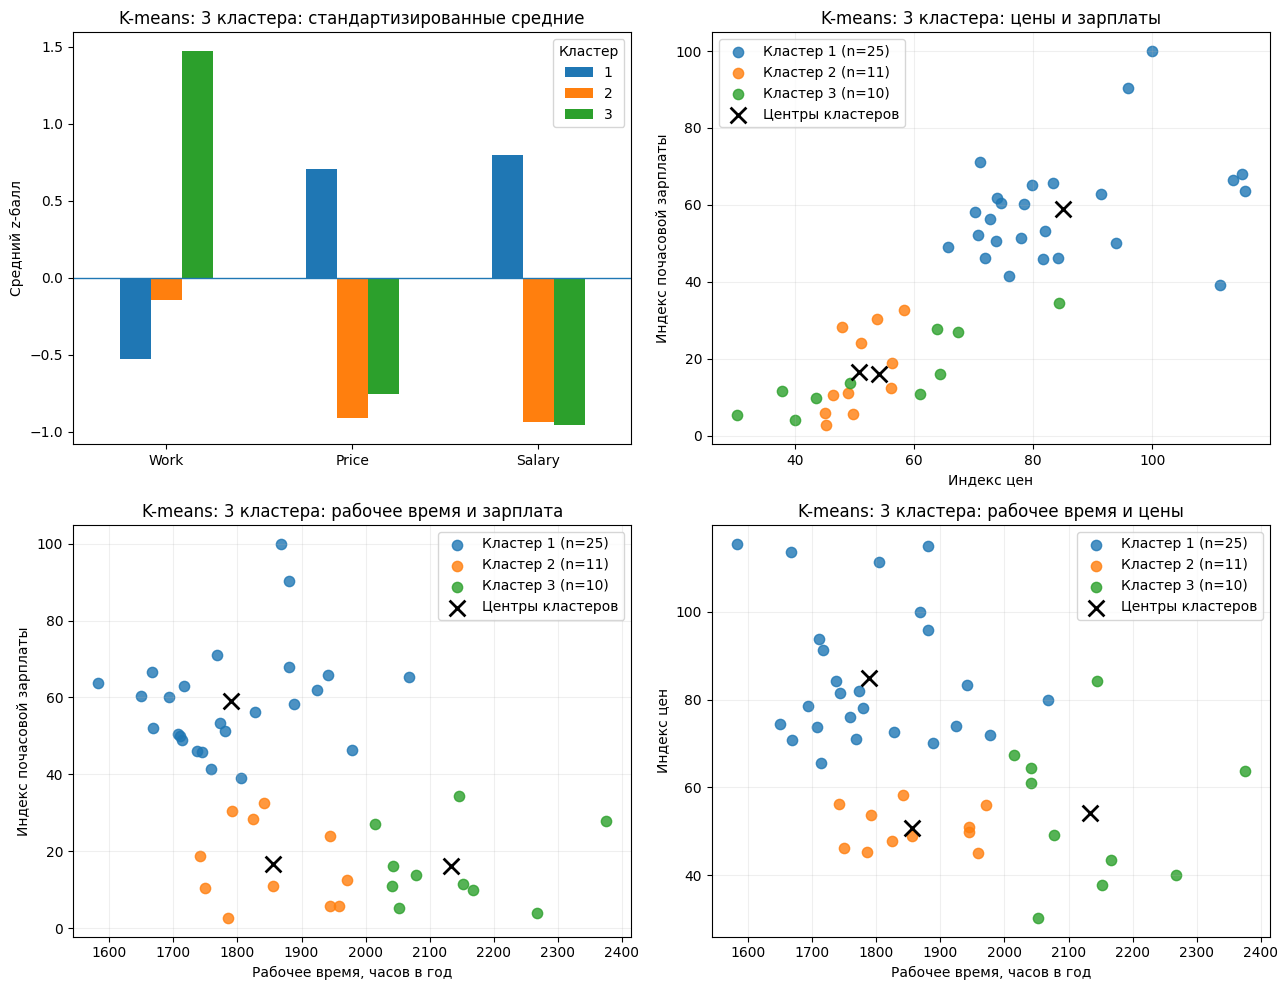

4 кластера: силуэт = 0.3658


,Cities,Work,Price,Salary
KMeans,,,,
1,6,1780.50,108.55,71.30
2,19,1792.00,77.53,55.16
3,11,1855.45,50.78,16.59
4,10,2133.50,54.17,16.08


Кластер 1 (6 городов): Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich
Кластер 2 (19 городов): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Paris, Sydney, Toronto, Vienna
Кластер 3 (11 городов): Athens, Buenos Aires, Johannesburg, Lagos, Lisbon, Mexico City, Nairobi, Nicosia, Rio de Janeiro, San Paulo, Seoul
Кластер 4 (10 городов): Bogota, Bombay, Caracas, Hong Kong, Kuala Lumpur, Manila, Panama, Singpore, Taipei, Tel Aviv


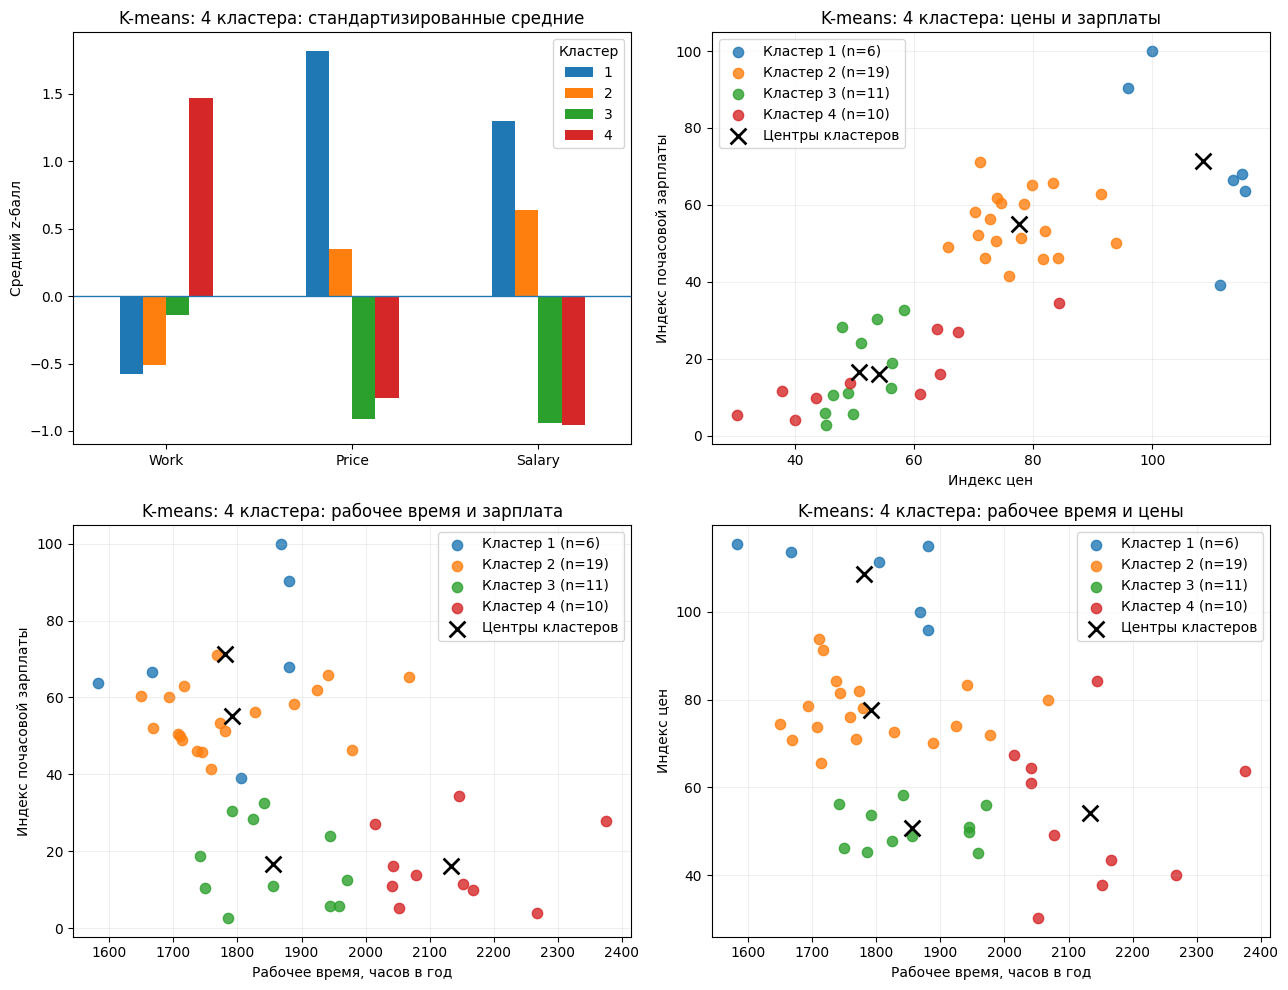

In [ ]:
# Сравниваем состав и профили трёх и четырёх групп.
for k in [3, 4]:
    alternative_labels2 = relabel_by_salary(cities2, km_models[k].labels_)
    alternative_cities2 = cities2.assign(KMeans=alternative_labels2)
    print(f'{k} кластера: силуэт = {silhouette_score(X2, alternative_labels2):.4f}')
    show_cluster_summary(alternative_cities2, 'KMeans', features2, assignments=False)
    plot_cluster_profiles(cities2, X2, alternative_labels2, features2, f'K-means: {k} кластера')


### Интерпретация кластеров

**При разбиении на 3 кластера:**

**Кластер 1 — 25 городов.** Например, Лондон, Нью-Йорк, Токио. Та же группа с более высокими ЗП и ценами при меньшем количестве рабочих часов в год.

**Кластер 2 — 11 городов.** Например, Афины, Мехико, Сеул. ЗП и цены ниже, работают в среднем около 1855 часов в год.

**Кластер 3 — 10 городов.** Например, Бомбей, Гонконг, Сингапур. ЗП и цены примерно как во втором кластере, а работают заметно больше — около 2134 часов в год.

**При разбиении на 4 кластера:**

**Кластер 1 — 6 городов.** Например, Цюрих, Женева, Токио. Самые высокие средние цены и почасовая оплата, без увеличенного количества рабочих часов.

**Кластер 2 — 19 городов.** Например, Лондон, Нью-Йорк, Париж. ЗП и цены выше, чем в третьем и четвёртом кластерах, но ниже, чем в первом. Рабочее время примерно как в первом кластере.

**Кластер 3 — 11 городов.** Например, Афины, Мехико, Сеул. Та же группа с более низкими ЗП и ценами и меньшим рабочим временем, чем в четвёртом кластере.

**Кластер 4 — 10 городов.** Например, Бомбей, Гонконг, Сингапур. ЗП и цены близки к третьему кластеру, но работают заметно больше.

Разделение на 3–4 группы менее чёткое: две группы с низкими ЗП почти не отличаются по ценам и зарплатам и разделяются в основном по рабочему времени. Силуэт снижается с 0,4705 до 0,3875 и 0,3658. Номера кластеров здесь упорядочены по средней зарплате, поэтому при смене k номера похожих групп могут меняться.


### Переходы городов и силуэты при трёх и четырёх группах


Переход от двух групп к 3:


3 кластера,1,2,3
Два кластера,,,
1,25,0,0
2,0,11,10


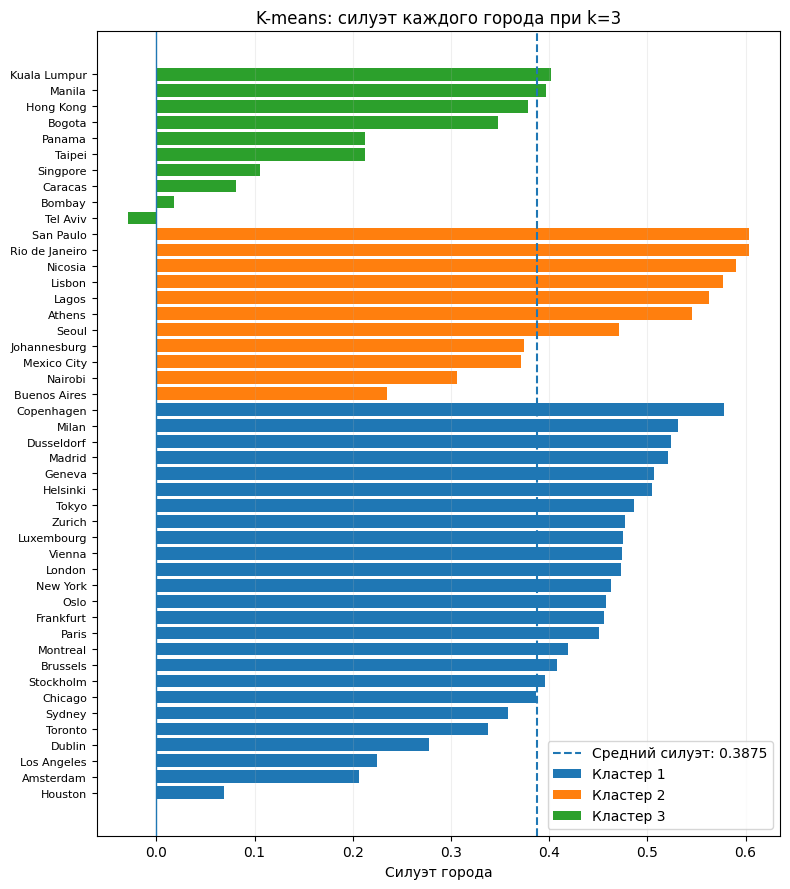

Городов с отрицательным силуэтом: 1
Города с силуэтом ниже 0,25:


,Город,Кластер,Силуэт
36,Tel_Aviv,3,-0.0292
37,Bombay,3,0.0176
0,Houston,1,0.0684
38,Caracas,3,0.0810
39,Singpore,3,0.1050
1,Amsterdam,1,0.2065
40,Taipei,3,0.2120
41,Panama,3,0.2122
2,Los_Angeles,1,0.2244
25,Buenos_Aires,2,0.2344


Ward и k-means при k=3, номера групп согласованы:


K-means,1,2,3
Ward,,,
1,25,0,0
2,0,7,0
3,0,4,10


Городов с разными назначениями: 4


,Город,Work,Price,Salary,Ward,KMeans
5,Buenos_Aires,1971.0,56.1,12.5,3,2
16,Johannesburg,1945.0,51.1,24.0,3,2
25,Mexico_City,1944.0,49.8,5.7,3,2
28,Nairobi,1958.0,45.0,5.8,3,2


Переход от двух групп к 4:


4 кластера,1,2,3,4
Два кластера,,,,
1,6,19,0,0
2,0,0,11,10


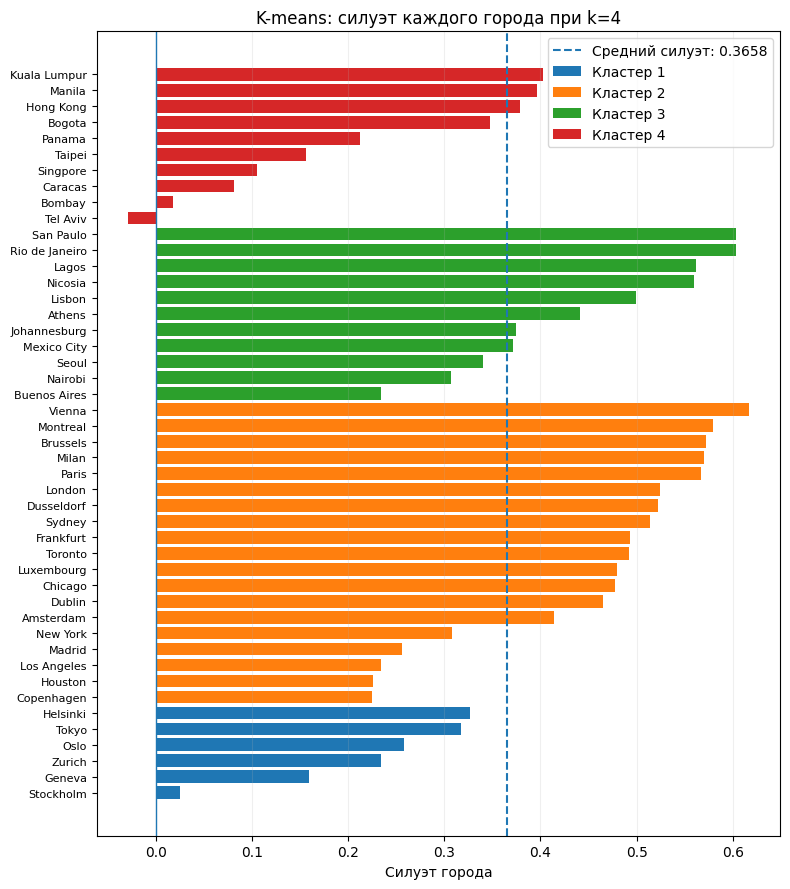

Городов с отрицательным силуэтом: 1
Города с силуэтом ниже 0,25:


,Город,Кластер,Силуэт
36,Tel_Aviv,4,-0.0292
37,Bombay,4,0.0176
0,Stockholm,1,0.0255
38,Caracas,4,0.0810
39,Singpore,4,0.1050
40,Taipei,4,0.1564
1,Geneva,1,0.1592
41,Panama,4,0.2122
6,Copenhagen,2,0.2249
7,Houston,2,0.2255


Ward и k-means при k=4, номера групп согласованы:


K-means,1,2,3,4
Ward,,,,
1,6,0,0,0
2,0,19,0,0
3,0,0,7,0
4,0,0,4,10


Городов с разными назначениями: 4


,Город,Work,Price,Salary,Ward,KMeans
5,Buenos_Aires,1971.0,56.1,12.5,4,3
16,Johannesburg,1945.0,51.1,24.0,4,3
25,Mexico_City,1944.0,49.8,5.7,4,3
28,Nairobi,1958.0,45.0,5.8,4,3


In [ ]:
# Прослеживаем переходы городов при увеличении числа групп.
for k in [3, 4]:
    detailed_labels = relabel_by_salary(cities2, km_models[k].labels_)
    print(f'Переход от двух групп к {k}:')
    display(pd.crosstab(pd.Series(km_labels, name='Два кластера'),
                        pd.Series(detailed_labels, name=f'{k} кластера')))
    # Показываем силуэты городов и расхождения между методами.
    show_city_silhouette(X2, detailed_labels, cities2.City,
                         f'K-means: силуэт каждого города при k={k}')
    compare_ward_kmeans(k, detailed_labels)


При трёх и четырёх группах отрицательный силуэт остаётся только у Тель-Авива, и он близок к нулю. Ward и k-means расходятся на одних и тех же четырёх городах: Буэнос-Айресе, Йоханнесбурге, Мехико и Найроби. K-means относит их к группе с меньшим рабочим временем. Таблицы показывают, что спорная граница проходит внутри городов с низкими зарплатами, а не между основными дорогой и дешёвой группами.


### Сравнение чувствительности


,k,Силуэт,ARI с Ward,Минимальный ARI при смене seed,ARI после заполнения,Минимальный ARI при исключении,Медианный ARI при исключении,Полных совпадений из 46,Город с минимальным ARI
0,2,0.4705,1.0000,1.0,1.0,1.0000,1.0,46,Нет изменений
1,3,0.3875,0.8622,1.0,1.0,0.4023,1.0,44,Rio_de_Janeiro
2,4,0.3658,0.8378,1.0,1.0,0.7200,1.0,32,Hong_Kong


Пять наиболее заметных изменений для каждого числа кластеров:


,Excluded_city,ARI,k
0,Amsterdam,1.0000,2
1,Athens,1.0000,2
2,Bogota,1.0000,2
3,Bombay,1.0000,2
4,Brussels,1.0000,2
80,Rio_de_Janeiro,0.4023,3
60,Hong_Kong,0.8652,3
46,Amsterdam,1.0000,3
47,Athens,1.0000,3
48,Bogota,1.0000,3


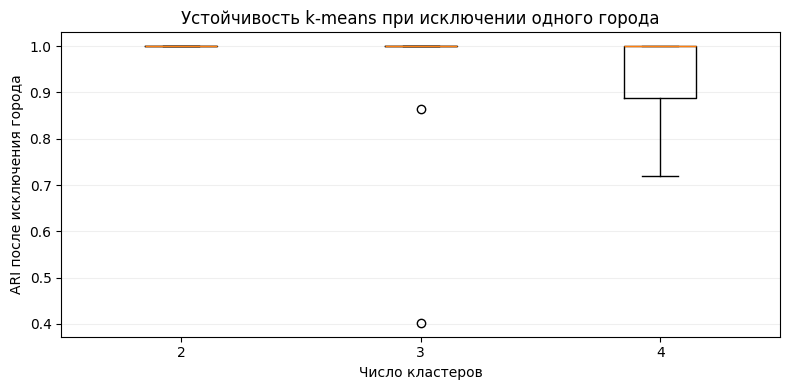

In [ ]:
# Готовим данные с заполненными пропусками.
filled2 = raw2.copy()
filled2[features2] = filled2[features2].fillna(filled2[features2].median())
X_filled2 = StandardScaler().fit_transform(filled2[features2])
comparison_rows2, loo_rows2, seed_rows2 = [], [], []
# Сравниваем устойчивость разбиений на две, три и четыре группы.
for k in [2, 3, 4]:
    baseline = km_models[k].labels_
    ward_labels = cut_tree(linkage(X2, method='ward'), n_clusters=k).ravel()
    # Повторяем разбиение с разными случайными начальными состояниями.
    if k not in seed_checks:
        seed_checks[k] = check_kmeans_seeds(X2, baseline, k)
    seed_rows2.extend(seed_checks[k][['seed', 'ARI']].assign(k=k).to_dict('records'))

    # Проверяем назначения полных городов после заполнения пропусков.
    imputed_model = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X_filled2)
    imputed = filled2[['City']].assign(Imputed=imputed_model.labels_)
    common = cities2[['City']].assign(Baseline=baseline).merge(imputed, on='City', validate='one_to_one')
    imputation_ari = adjusted_rand_score(common.Baseline, common.Imputed)

    # Исключаем по одному городу и сравниваем оставшиеся назначения.
    current_table = check_leave_one_out(
        cities2, features2, baseline,
        lambda points: KMeans(n_clusters=k, n_init=50, random_state=42).fit_predict(points))
    current_loo = current_table.ARI.to_numpy()
    loo_rows2.extend(current_table.assign(k=k).to_dict('records'))
    seed_ari = [row['ARI'] for row in seed_rows2 if row['k'] == k]
    comparison_rows2.append({
        'k': k, 'Силуэт': silhouette_score(X2, baseline),
        'ARI с Ward': adjusted_rand_score(baseline, ward_labels),
        'Минимальный ARI при смене seed': min(seed_ari),
        'ARI после заполнения': imputation_ari,
        'Минимальный ARI при исключении': current_loo.min(),
        'Медианный ARI при исключении': np.median(current_loo),
        'Полных совпадений из 46': np.isclose(current_loo, 1).sum(),
        'Город с минимальным ARI': ('Нет изменений' if np.isclose(current_loo, 1).all()
                                  else cities2.loc[current_loo.argmin(), 'City'])})

# Сводим результаты проверок в таблицы.
comparison2 = pd.DataFrame(comparison_rows2)
loo2 = pd.DataFrame(loo_rows2)
seeds2 = pd.DataFrame(seed_rows2)
display(comparison2.round(4))
print('Пять наиболее заметных изменений для каждого числа кластеров:')
display(loo2.sort_values(['k', 'ARI', 'Excluded_city']).groupby('k').head(5).round(4))
# Показываем распределение изменений при исключении городов.
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([loo2.loc[loo2.k.eq(k), 'ARI'] for k in [2, 3, 4]])
ax.set(xticks=[1, 2, 3], xticklabels=['2', '3', '4'],
       xlabel='Число кластеров', ylabel='ARI после исключения города',
       title='Устойчивость k-means при исключении одного города')
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()
# Сохраняем результаты проверок устойчивости.
comparison2.to_csv('lab2_sensitivity_summary.csv', index=False, encoding='utf-8-sig')
loo2.to_csv('lab2_sensitivity_leave_one_out.csv', index=False, encoding='utf-8-sig')
seeds2.to_csv('lab2_sensitivity_seeds.csv', index=False, encoding='utf-8-sig')


### Результаты сравнения

При смене случайного начального состояния все 30 запусков с n_init=50 дают те же разбиения: ARI = 1 для 2, 3 и 4 групп. Медианное заполнение пропусков тоже не меняет назначения исходных 46 городов.

При исключении одного города разбиение на **2 кластера сохраняется во всех 46 проверках**. Для **3 кластеров — в 44 из 46**: удаление Рио-де-Жанейро сильно меняет результат, ARI падает до **0,4023**. Для **4 кластеров — в 32 из 46**, минимальный ARI **0,7200** при удалении Гонконга. Медианный ARI во всех случаях равен 1.

По сравнению с Ward разбиения на 3 и 4 группы уже различаются: ARI равен 0,8622 и 0,8378. Две группы совпадают полностью.

**Разбиение на 3–4 кластера менее чёткое и более чувствительное к отдельным городам.** При трёх группах изменения редкие, но иногда сильные; при четырёх происходят чаще. Более низкий силуэт и эти проверки поддерживают выбор двух групп. Проверенные случайные инициализации при 50 попытках сами по себе не добавляют нестабильности.


### Сравнение разбиений по ИЧР и продолжительности жизни

Сопоставим те же города с известными национальными показателями при 2, 3 и 4 группах. Национальные показатели не участвуют в построении этих разбиений. Определение η² и источники данных приведены в разделе «Сравнение со сторонними показателями».


2 кластера
Городов с двумя показателями: 45/46; в кластерах: 45; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,25,19,0.841,0.848,0.774,0.878,76.395,76.192,75.025,79.037
Кластер 2,20,19,0.663,0.670,0.383,0.826,68.798,71.196,45.483,77.873


3 кластера
Городов с двумя показателями: 45/46; в кластерах: 45; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,25,19,0.841,0.848,0.774,0.878,76.395,76.192,75.025,79.037
Кластер 2,11,10,0.655,0.670,0.383,0.780,67.230,69.368,45.483,77.137
Кластер 3,9,9,0.673,0.669,0.448,0.826,70.714,71.219,59.032,77.873


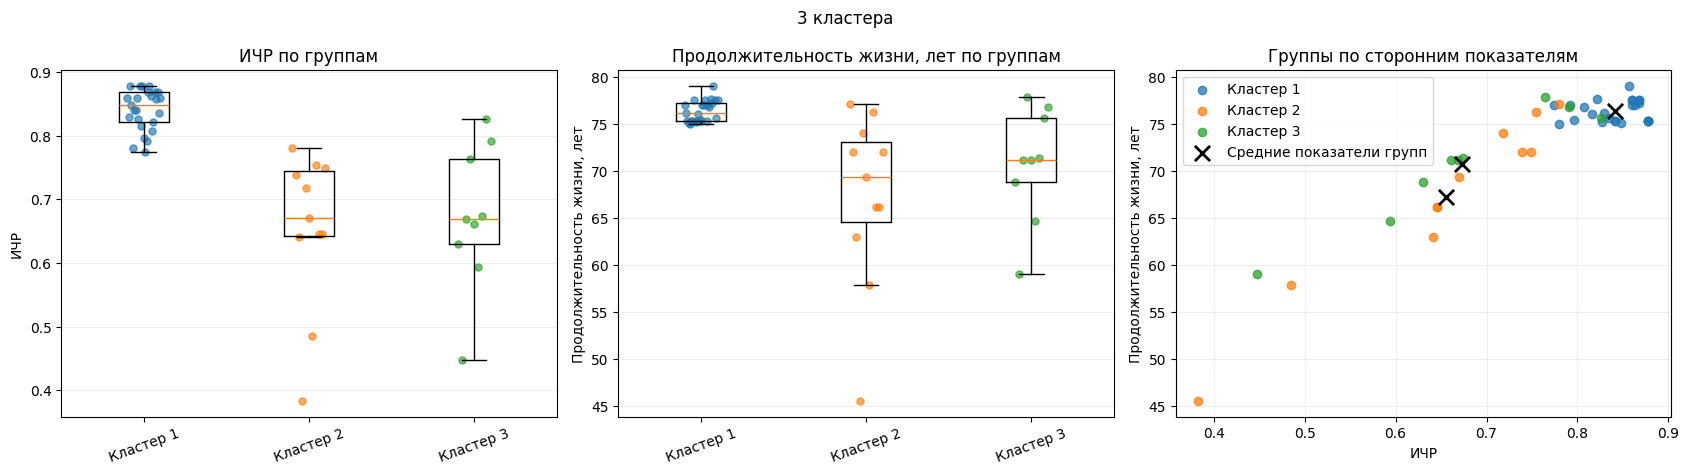

4 кластера
Городов с двумя показателями: 45/46; в кластерах: 45; шум с показателями: 0


,Cities,Countries,HDI_mean,HDI_median,HDI_min,HDI_max,Life_mean,Life_median,Life_min,Life_max
Кластер 1,6,5,0.848,0.858,0.821,0.863,77.324,77.515,75.228,79.037
Кластер 2,19,14,0.839,0.841,0.774,0.878,76.102,75.617,75.025,77.593
Кластер 3,11,10,0.655,0.670,0.383,0.780,67.230,69.368,45.483,77.137
Кластер 4,9,9,0.673,0.669,0.448,0.826,70.714,71.219,59.032,77.873


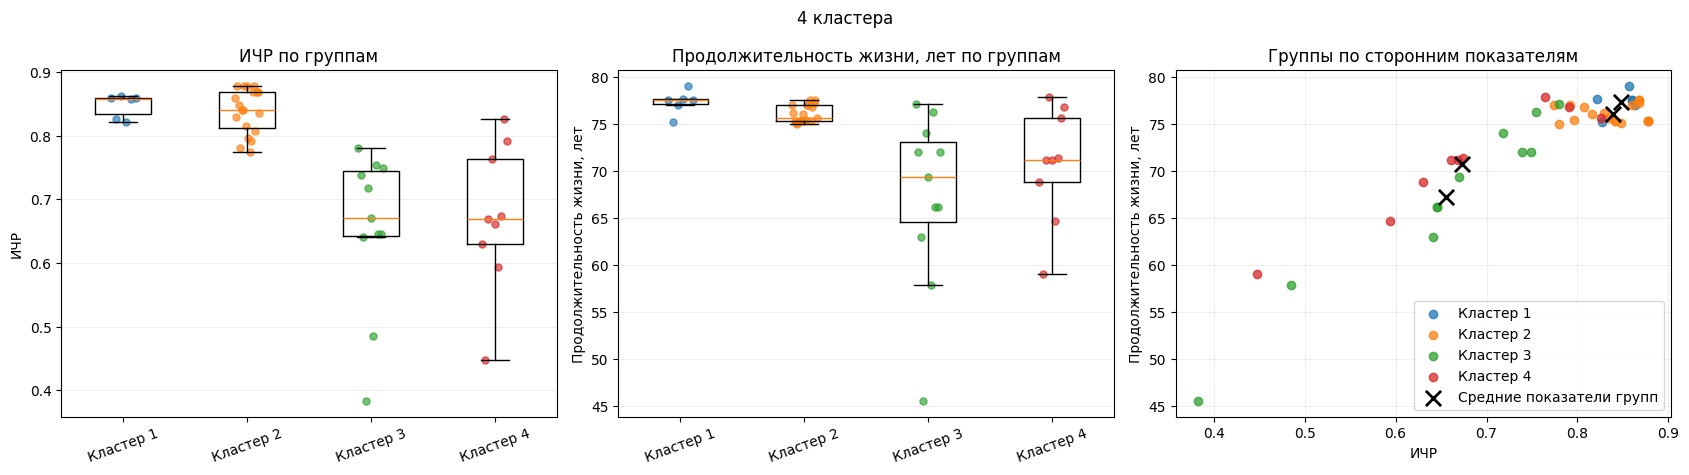

,Городов в оценке,Стран в оценке,η²: ИЧР,"η²: ИЧР, равный вес стран",η²: Продолжительность жизни,"η²: Продолжительность жизни, равный вес стран"
Кластеров,,,,,,
2,45,38,0.5563,0.4969,0.3414,0.3073
3,45,38,0.5588,0.4993,0.3734,0.3380
4,45,38,0.5594,0.5014,0.3770,0.3404


In [ ]:
# Сравниваем сторонние показатели при двух, трёх и четырёх группах.
external_k_rows = []
for k in [2, 3, 4]:
    alternative_external_labels = relabel_by_salary(cities2, km_models[k].labels_)
    external_result = compare_living_standards(
        cities2, alternative_external_labels, f'{k} кластера', plots=k != 2)
    external_k_rows.append({'Кластеров': k, **external_result})
external_k_comparison = pd.DataFrame(external_k_rows).set_index('Кластеров')
display(external_k_comparison.round(4))


### Вывод по сторонним показателям

При **3 группах** два подкластера второй исходной группы имеют средний ИЧР **0,655 и 0,673**, продолжительность жизни — **67,2 и 70,7 года**. При **4 группах** дополнительно разделяется первая исходная группа: ИЧР **0,848 и 0,839**, продолжительность жизни **77,3 и 76,1 года**.

По ИЧР выигрыш минимален: η² **0,556 → 0,559**. По продолжительности жизни различия немного сильнее: **0,341 → 0,377**. При равном весе стран — **0,497 → 0,501** и **0,307 → 0,340** соответственно. Три группы дают некоторое уточнение по продолжительности жизни, четвёртая добавляет мало. Увеличение числа кластеров не превращает их в чёткие категории национального уровня жизни и само по себе повышает η².
